<img src="img/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Applied Neural Networks: Projekt </b> <br> FS 2026 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

1. [Einleitung](01_Einleitung.ipynb)
2. **Datenerzeugung**
3. [ESN-Baseline auf sauberen Daten](03_ESN_Baseline_Clean.ipynb)
4. [Robustheit gegenüber Rauschen](04_Rauschen_Robustheit.ipynb)
5. [Out-of-Distribution-Analyse](05_Out_of_Distribution.ipynb)
6. [Schlussauswertung](06_Schluss.ipynb)

---

# 2. Datenerzeugung

In diesem Notebook werden synthetische gedämpfte Schwingungen erzeugt. Die Daten dienen als Grundlage für alle folgenden Experimente.

Die Schwingungen folgen der Gleichung

$$
y(t) = A e^{-\alpha t} \sin(\omega t + \varphi)
$$

Es werden drei Arten von Daten erzeugt:

1. Trainingsdaten innerhalb des definierten Parameterbereichs
2. In-Distribution-Testdaten innerhalb desselben Parameterbereichs
3. Out-of-Distribution-Testdaten ausserhalb des Trainingsbereichs

In diesem Notebook wird noch kein Modell trainiert. Das ESN wird erst im nächsten Notebook definiert und trainiert.

In [11]:
import os
import numpy as np
import pandas as pd

from utils import data_utils as du

## 2.1. Parameterbereiche

Zuerst werden die globalen Einstellungen und Parameterbereiche definiert.

Für Trainings- und In-Distribution-Testdaten werden dieselben Bereiche verwendet:

| Parameter | Symbol | Bedeutung |
|---|---|---|
| Amplitude | $A$ | Maximale Auslenkung |
| Dämpfungskonstante | $\alpha$ | Wie schnell die Schwingung abklingt |
| Kreisfrequenz | $\omega$ | Wie schnell die Schwingung schwingt |
| Phase | $\varphi$ | Verschiebung des Startzeitpunkts |

Die Frequenz wird im Code über `omega_factor` definiert. Dabei gilt:

$$
\omega = \text{omega\_factor} \cdot \pi
$$

Das macht die Wertebereiche im Code besser lesbar.

In [12]:
os.makedirs("data", exist_ok=True)

T_MIN = 0
T_MAX = 20
N_STEPS = 1000

N_TRAIN = 25
N_TEST = 25
N_OOD = 25

PARAM_RANGES_ID = {
    "A": (0.5, 2.0),
    "alpha": (0.01, 0.15),
    "omega_factor": (1.0, 4.0),  # omega = omega_factor * pi
    "phi": (0.0, 2 * np.pi),
}

t = np.linspace(T_MIN, T_MAX, N_STEPS)

## 2.2. Trainingsdaten erzeugen

Die Trainingsdaten werden innerhalb des definierten Parameterbereichs erzeugt.

Im Gegensatz zu den späteren Testdaten werden sie nicht vollständig zufällig erzeugt. Stattdessen werden Amplitude und Frequenz strukturiert über den Wertebereich verteilt. Dadurch soll das ESN später möglichst unterschiedliche Schwingungsformen im Training sehen.

Die Trainingsdaten werden gespeichert als:

```text
data/train_clean.npy
```

In [13]:
train_clean = du.generate_diverse_oscillations(
    n=N_TRAIN,
    t=t,
    param_ranges=PARAM_RANGES_ID,
    seed=42
)

du.save_dataset("data/train_clean.npy", train_clean)

print("Beispiel-Parameter:")
print(train_clean[0]["params"])

data/train_clean.npy: saved, 25 oscillations
Beispiel-Parameter:
{'A': np.float64(0.5273956048555963), 'alpha': 0.030480993855095773, 'omega': np.float64(3.366906371747029), 'phi': 4.381692553882582}


## 2.3. In-Distribution-Testdaten erzeugen

Die In-Distribution-Testdaten werden aus denselben Parameterbereichen wie die Trainingsdaten erzeugt.

Im Unterschied zu den Trainingsdaten werden die Parameter hier vollständig zufällig gezogen. Dadurch entstehen neue, ungesehene Schwingungen, die aber weiterhin innerhalb der Trainingsverteilung liegen.

Die Testdaten werden gespeichert als:

```text
data/test_clean_id.npy
```

In [14]:
test_clean_id = du.generate_random_oscillations(
    n=N_TEST,
    t=t,
    param_ranges=PARAM_RANGES_ID,
    seed=99
)

du.save_dataset("data/test_clean_id.npy", test_clean_id)

print("Beispiel-Parameter:")
print(test_clean_id[0]["params"])

data/test_clean_id.npy: saved, 25 oscillations
Beispiel-Parameter:
{'A': 1.2590460118225917, 'alpha': 0.08911282844982835, 'omega': 7.96628690826155, 'phi': 6.108427129246479}


## 2.4. Out-of-Distribution-Daten erzeugen

Zusätzlich werden vier Out-of-Distribution-Datensätze erzeugt.

Diese Datensätze unterscheiden sich gezielt von den Trainingsdaten:

| Datensatz | Änderung |
|---|---|
| High amplitude | $A$ von 2.0 bis 3.0 |
| High damping | $\alpha$ von 0.15 bis 0.30 |
| High frequency | $\omega$ von $4\pi$ bis $6\pi$ |
| Combined | $A$, $\alpha$ und $\omega$ ausserhalb des Trainingsbereichs |

Die OOD-Daten bleiben sauber. Es wird hier also kein Rauschen hinzugefügt.

In [15]:
PARAM_RANGES_OOD_HIGH_AMPLITUDE = {
    "A": (2.0, 3.0),
    "alpha": (0.01, 0.15),
    "omega_factor": (1.0, 4.0),
    "phi": (0.0, 2 * np.pi),
}

PARAM_RANGES_OOD_HIGH_DAMPING = {
    "A": (0.5, 2.0),
    "alpha": (0.15, 0.30),
    "omega_factor": (1.0, 4.0),
    "phi": (0.0, 2 * np.pi),
}

PARAM_RANGES_OOD_HIGH_FREQUENCY = {
    "A": (0.5, 2.0),
    "alpha": (0.01, 0.15),
    "omega_factor": (4.0, 6.0),
    "phi": (0.0, 2 * np.pi),
}

PARAM_RANGES_OOD_COMBINED = {
    "A": (2.0, 3.0),
    "alpha": (0.15, 0.30),
    "omega_factor": (4.0, 6.0),
    "phi": (0.0, 2 * np.pi),
}

In [16]:
test_ood_high_amplitude = du.generate_random_oscillations(
    n=N_OOD,
    t=t,
    param_ranges=PARAM_RANGES_OOD_HIGH_AMPLITUDE,
    seed=101
)

test_ood_high_damping = du.generate_random_oscillations(
    n=N_OOD,
    t=t,
    param_ranges=PARAM_RANGES_OOD_HIGH_DAMPING,
    seed=102
)

test_ood_high_frequency = du.generate_random_oscillations(
    n=N_OOD,
    t=t,
    param_ranges=PARAM_RANGES_OOD_HIGH_FREQUENCY,
    seed=103
)

test_ood_combined = du.generate_random_oscillations(
    n=N_OOD,
    t=t,
    param_ranges=PARAM_RANGES_OOD_COMBINED,
    seed=104
)

du.save_dataset("data/test_ood_high_amplitude.npy", test_ood_high_amplitude)
du.save_dataset("data/test_ood_high_damping.npy", test_ood_high_damping)
du.save_dataset("data/test_ood_high_frequency.npy", test_ood_high_frequency)
du.save_dataset("data/test_ood_combined.npy", test_ood_combined)

data/test_ood_high_amplitude.npy: saved, 25 oscillations
data/test_ood_high_damping.npy: saved, 25 oscillations
data/test_ood_high_frequency.npy: saved, 25 oscillations
data/test_ood_combined.npy: saved, 25 oscillations


## 2.5. Trainings- und In-Distribution-Testdaten visualisieren

Zur Kontrolle werden die erzeugten Trainingsdaten und In-Distribution-Testdaten geplottet.

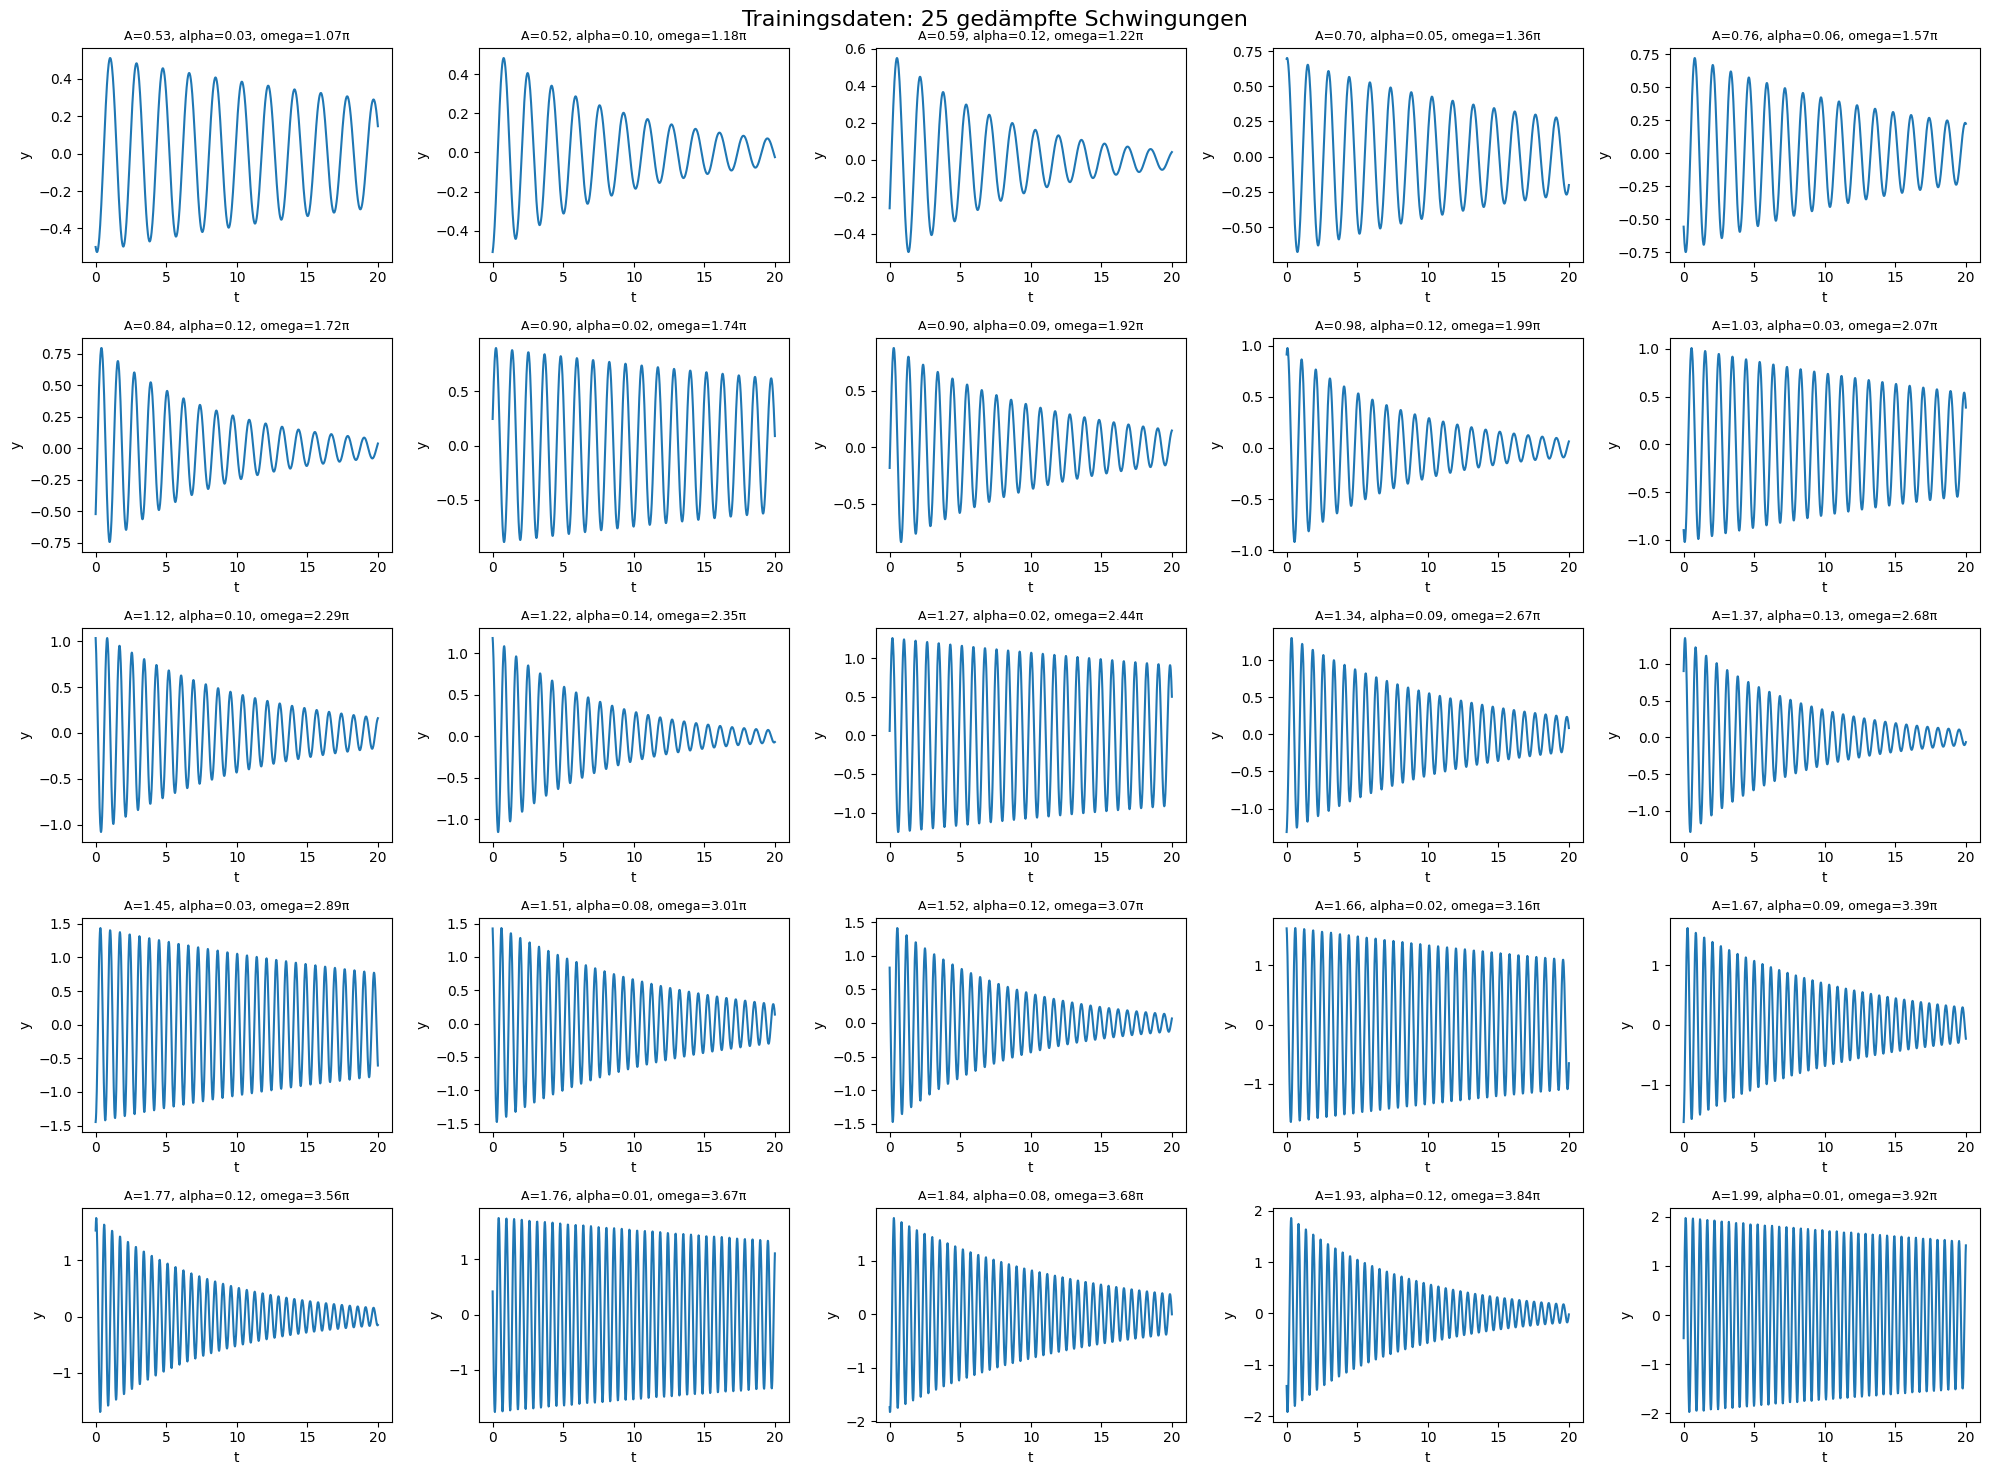

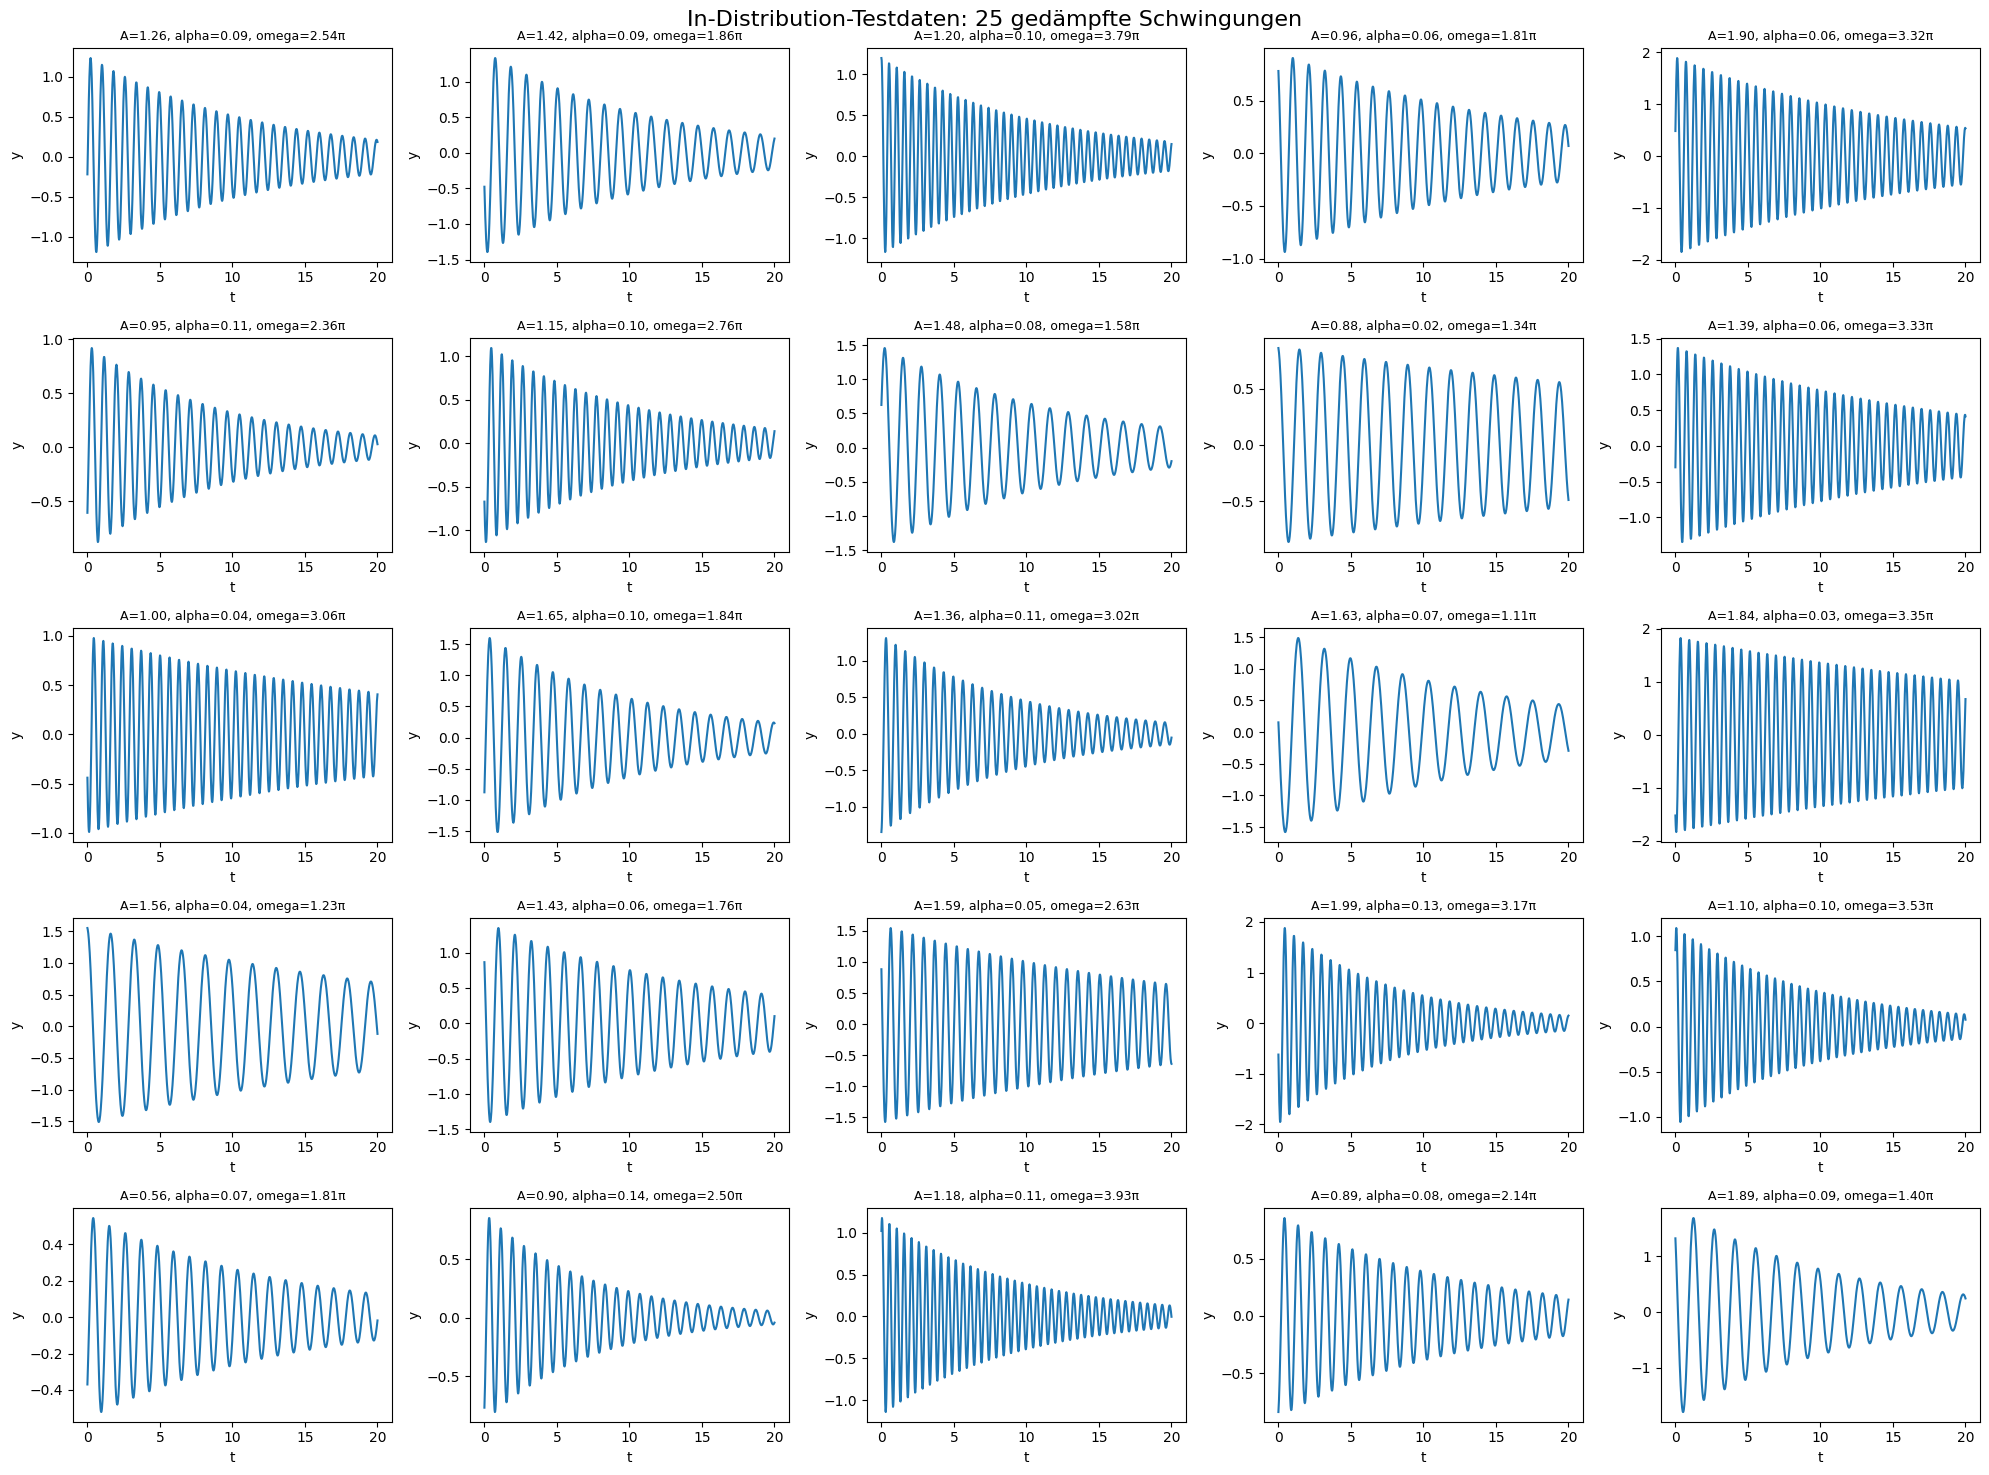

In [17]:
du.plot_oscillation_grid(
    train_clean,
    "Trainingsdaten: 25 gedämpfte Schwingungen"
)

du.plot_oscillation_grid(
    test_clean_id,
    "In-Distribution-Testdaten: 25 gedämpfte Schwingungen"
)

Die Trainingsdaten zeigen eine strukturierte Abdeckung verschiedener Amplituden, Dämpfungen und Frequenzen.

Die In-Distribution-Testdaten sind zufälliger verteilt, liegen aber weiterhin im gleichen Parameterbereich wie die Trainingsdaten.

## 2.6. OOD-Beispiele visualisieren

Für die Out-of-Distribution-Daten werden pro Szenario drei Beispielschwingungen dargestellt.

Dadurch wird sichtbar, wie sich höhere Amplitude, stärkere Dämpfung und höhere Frequenz auf die Signalform auswirken.

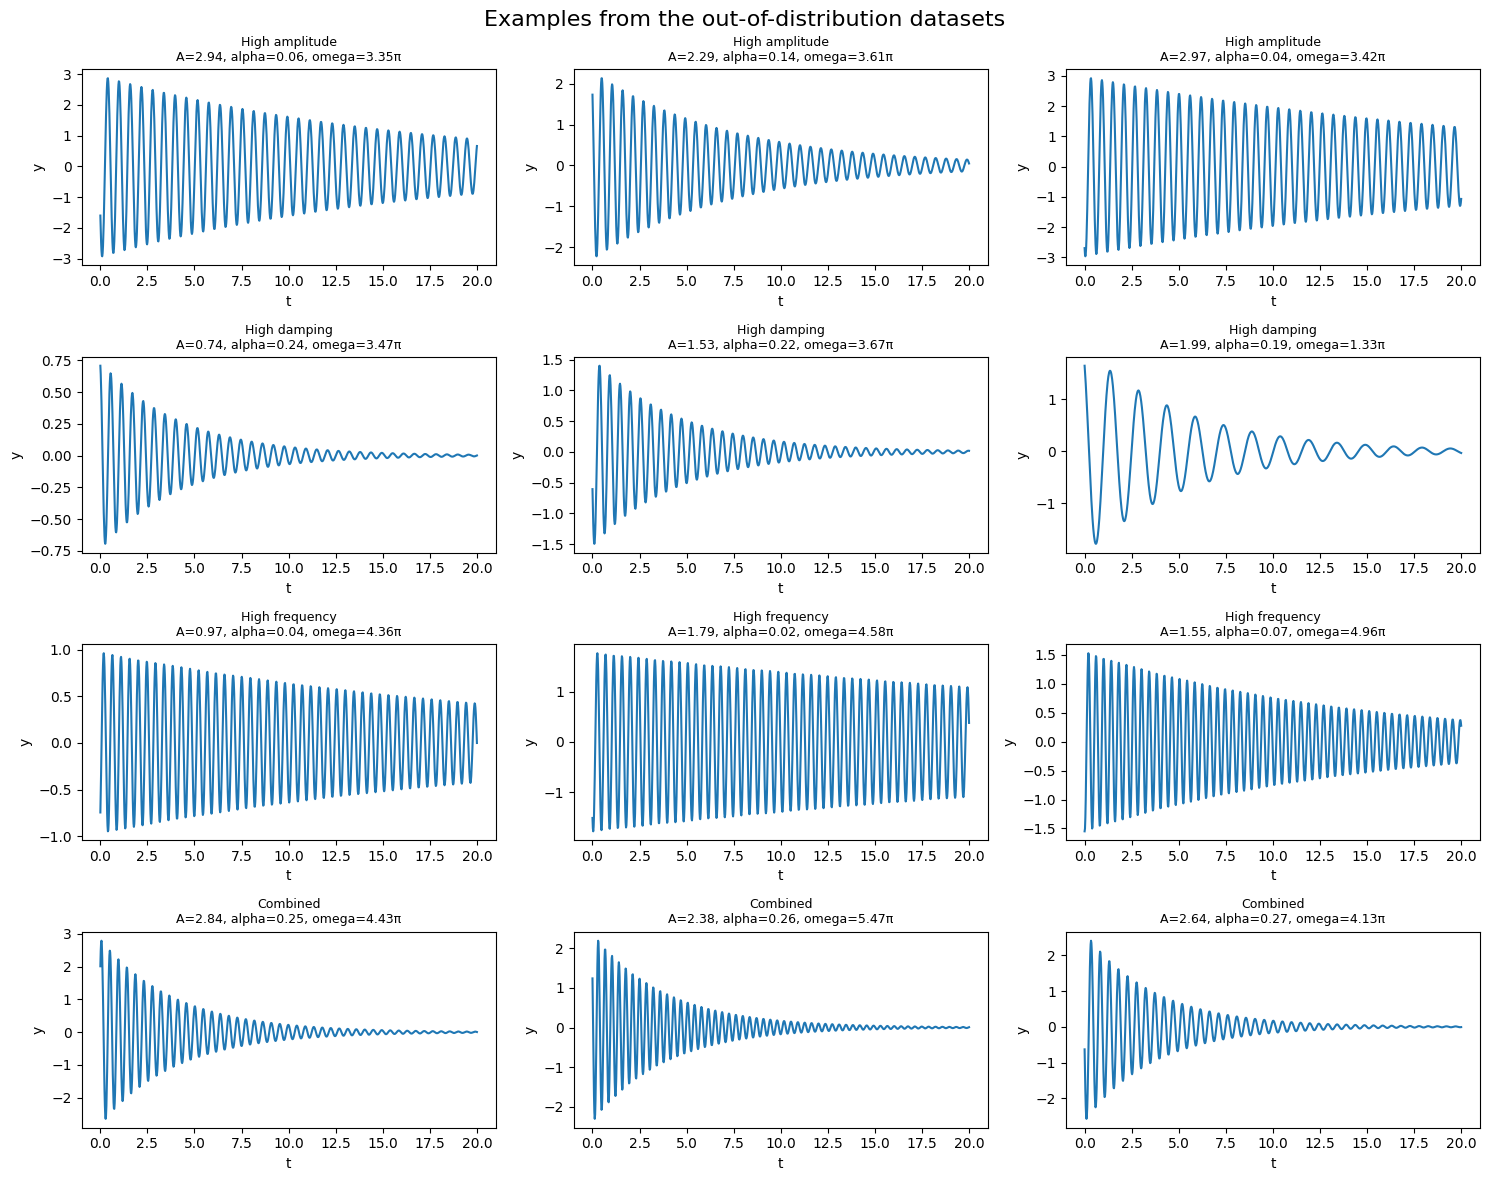

In [18]:
ood_sets = {
    "High amplitude": test_ood_high_amplitude,
    "High damping": test_ood_high_damping,
    "High frequency": test_ood_high_frequency,
    "Combined": test_ood_combined,
}

du.plot_ood_examples(ood_sets, n_examples=3)

Die OOD-Beispiele zeigen gezielt veränderte Eigenschaften:

- Bei `High amplitude` sind die Ausschläge grösser.
- Bei `High damping` klingt das Signal schneller ab.
- Bei `High frequency` schwingt das Signal schneller.
- Bei `Combined` treten mehrere dieser Änderungen gleichzeitig auf.

## 2.7. Parameterverteilungen prüfen

Zum Schluss werden die verwendeten Parameter der Datensätze tabellarisch und grafisch überprüft.

Diese Kontrolle ist wichtig, damit klar ist, welche Daten innerhalb des Trainingsbereichs liegen und welche bewusst ausserhalb erzeugt wurden.

In [19]:
df_params = pd.concat([
    du.extract_parameter_table("Train clean", train_clean),
    du.extract_parameter_table("Test clean ID", test_clean_id),
    du.extract_parameter_table("OOD high amplitude", test_ood_high_amplitude),
    du.extract_parameter_table("OOD high damping", test_ood_high_damping),
    du.extract_parameter_table("OOD high frequency", test_ood_high_frequency),
    du.extract_parameter_table("OOD combined", test_ood_combined),
], ignore_index=True)

df_summary = du.create_parameter_summary(df_params)

df_summary

,Dataset,A range,alpha range,omega range,Count
0,OOD combined,2.25–2.97,0.16–0.30,4.13π–5.97π,25
1,OOD high amplitude,2.06–2.98,0.01–0.15,1.10π–3.98π,25
2,OOD high damping,0.60–1.99,0.16–0.30,1.17π–3.99π,25
3,OOD high frequency,0.53–1.99,0.01–0.15,4.03π–5.84π,25
4,Test clean ID,0.56–1.99,0.02–0.14,1.11π–3.93π,25
5,Train clean,0.52–1.99,0.01–0.14,1.07π–3.92π,25


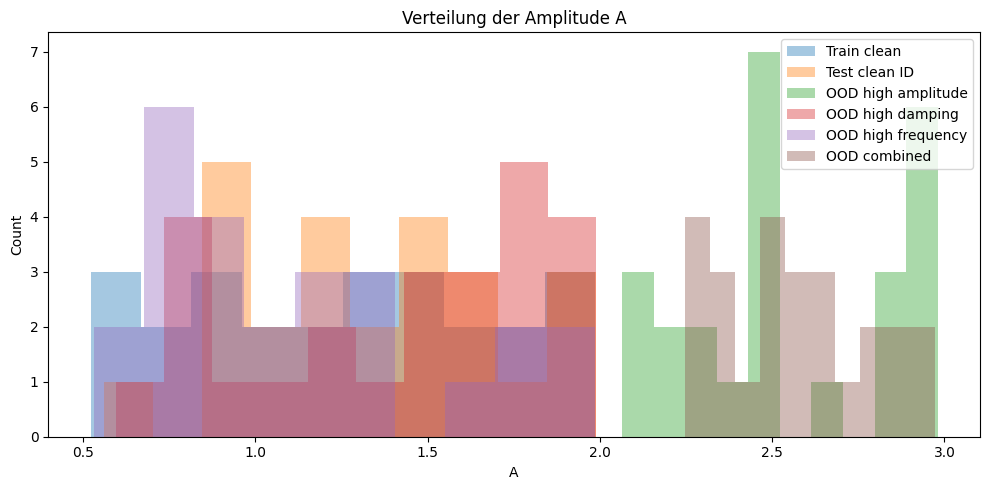

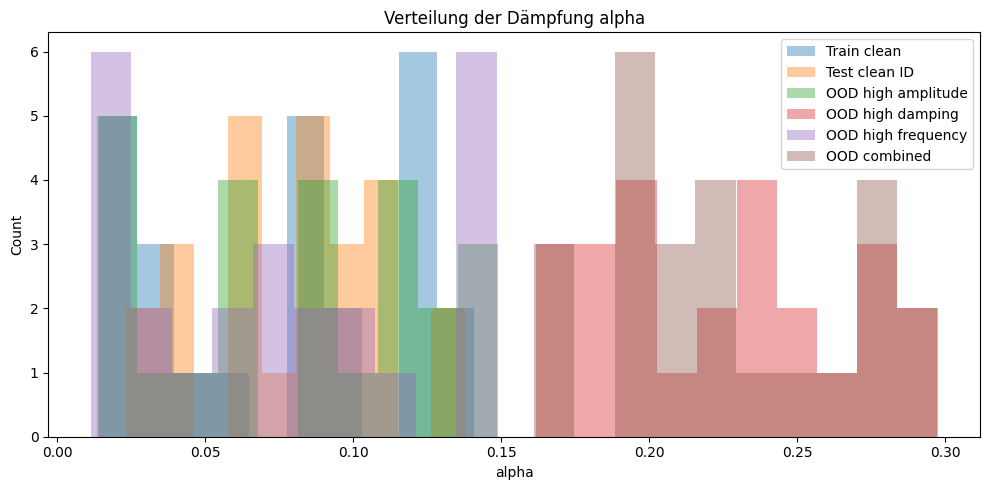

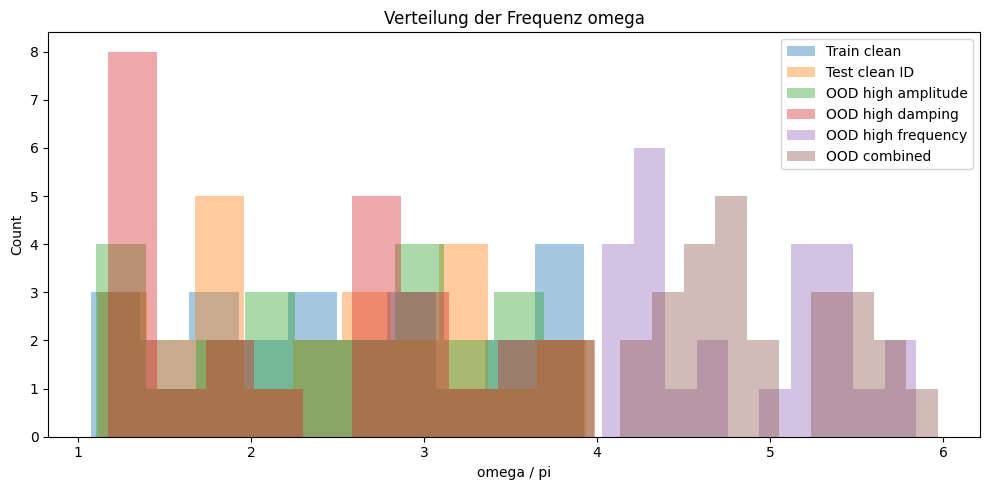

In [20]:
du.plot_parameter_distribution(
    df_params,
    parameter="A",
    title="Verteilung der Amplitude A",
    xlabel="A"
)

du.plot_parameter_distribution(
    df_params,
    parameter="alpha",
    title="Verteilung der Dämpfung alpha",
    xlabel="alpha"
)

du.plot_parameter_distribution(
    df_params,
    parameter="omega_pi",
    title="Verteilung der Frequenz omega",
    xlabel="omega / pi"
)

## 2.8. Ergebnis

Dieses Notebook erzeugt und speichert folgende Datensätze:

- `data/train_clean.npy`
- `data/test_clean_id.npy`
- `data/test_ood_high_amplitude.npy`
- `data/test_ood_high_damping.npy`
- `data/test_ood_high_frequency.npy`
- `data/test_ood_combined.npy`

Damit ist die Datengrundlage für die Baseline-, Rausch- und Out-of-Distribution-Experimente vorbereitet.

---

<div style="display: flex; justify-content: space-between; margin-top: 30px;">
  <a href="01_Einleitung.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Zurück
    </button>
  </a>
  <a href="03_ESN_Baseline_Clean.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Weiter
    </button>
  </a>
</div>